In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# لود کردن داده خام
df = pd.read_csv("../data/raw/Telco-Customer-Churn.csv")

# --- تکرار مراحل پاک‌سازی از نوت‌بوک اول ---
# ۱. تبدیل TotalCharges به عدد و حذف NaN ها
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df = df.dropna(subset=['TotalCharges'])

# ۲. حذف customerID
df_model = df.drop('customerID', axis=1)

# ۳. تبدیل Churn به 0 و 1
df_model['Churn'] = df_model['Churn'].map({'No': 0, 'Yes': 1})

# ۴. تبدیل متغیرهای متنی به عدد
df_model = pd.get_dummies(df_model, drop_first=True)

print("داده‌ها برای مدل‌سازی آماده شدند. ابعاد:", df_model.shape)

داده‌ها برای مدل‌سازی آماده شدند. ابعاد: (7032, 31)


In [2]:
from sklearn.model_selection import train_test_split

# جدا کردن متغیر هدف (Churn) از بقیه ویژگی‌ها
X = df_model.drop('Churn', axis=1)
y = df_model['Churn']

# تقسیم داده‌ها: ۸۰٪ برای آموزش و ۲۰٪ برای تست
# random_state=42 برای اینه که هر بار کد رو اجرا کردی، تقسیم‌بندی یکسان بمونه
# stratify=y برای اینه که نسبت ۰ و ۱ توی هر دو بخش Train و Test حفظ بشه (به خاطر عدم تعادل داده)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("ابعاد داده آموزش (Train):", X_train.shape)
print("ابعاد داده آزمون (Test):", X_test.shape)

ابعاد داده آموزش (Train): (5625, 30)
ابعاد داده آزمون (Test): (1407, 30)


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# ۱. ساخت مدل (max_iter=1000 برای اینه که مطمئن بشیم الگوریتم زودتر از موعد متوقف نمیشه)
model_lr = LogisticRegression(max_iter=1000)

# ۲. آموزش مدل با داده‌های Train
model_lr.fit(X_train, y_train)

# ۳. پیش‌بینی روی داده‌های Test (داده‌هایی که مدل تا حالا ندیده)
y_pred_lr = model_lr.predict(X_test)

# ۴. محاسبه دقت (Accuracy)
accuracy = accuracy_score(y_test, y_pred_lr)
print(f"Accuracy: {accuracy * 100:.2f}%")
print("-" * 30)

# ۵. گزارش کامل‌تر (Precision, Recall, F1-score)
print("Classification Report:")
print(classification_report(y_test, y_pred_lr))

Accuracy: 80.31%
------------------------------
Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



C:\Users\T3mplaR\Desktop\پروژه ساخت هوش مصنوعی\churn-project\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# ۱. ساخت استانداردساز
scaler = StandardScaler()

# ۲. آموزش استانداردساز روی داده‌های Train و تبدیل کردن آنها
X_train_scaled = scaler.fit_transform(X_train)

# ۳. تبدیل داده‌های Test (فقط transform می‌کنیم، چون نباید از داده تست چیزی یاد بگیره)
X_test_scaled = scaler.transform(X_test)

# ۴. ساخت مدل جدید
model_lr_scaled = LogisticRegression(max_iter=1000)

# ۵. آموزش روی داده‌های استاندارد شده
model_lr_scaled.fit(X_train_scaled, y_train)

# ۶. پیش‌بینی
y_pred_lr_scaled = model_lr_scaled.predict(X_test_scaled)

# ۷. ارزیابی
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr_scaled) * 100:.2f}%")
print("-" * 30)
print("Classification Report:")
print(classification_report(y_test, y_pred_lr_scaled))

Accuracy: 80.38%
------------------------------
Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# ۱. ساخت مدل Random Forest
# n_estimators=100 یعنی ۱۰۰ درخت تصمیم‌گیری با هم رای می‌دن
# random_state=42 برای تکرارپذیری نتایج
model_rf = RandomForestClassifier(n_estimators=100, random_state=42)

# ۲. آموزش مدل
model_rf.fit(X_train, y_train) # برای درخت‌ها نیازی به Scaling نیست

# ۳. پیش‌بینی روی داده تست
y_pred_rf = model_rf.predict(X_test)

# ۴. ارزیابی
print(f"Random Forest Accuracy: {accuracy_score(y_test, y_pred_rf) * 100:.2f}%")
print("-" * 30)
print("Classification Report (Random Forest):")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 78.96%
------------------------------
Classification Report (Random Forest):
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1033
           1       0.63      0.52      0.57       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# ساخت مدل با پارامتر class_weight='balanced'
model_rf_balanced = RandomForestClassifier(
    n_estimators=100, 
    random_state=42, 
    class_weight='balanced'  # این پارامتر جادویی!
)

# آموزش
model_rf_balanced.fit(X_train, y_train)

# پیش‌بینی
y_pred_rf_balanced = model_rf_balanced.predict(X_test)

# ارزیابی
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf_balanced) * 100:.2f}%")
print("-" * 30)
print("Classification Report (Balanced):")
print(classification_report(y_test, y_pred_rf_balanced))

Accuracy: 76.83%
------------------------------
Classification Report (Balanced):
              precision    recall  f1-score   support

           0       0.87      0.80      0.84      1033
           1       0.55      0.67      0.61       374

    accuracy                           0.77      1407
   macro avg       0.71      0.74      0.72      1407
weighted avg       0.79      0.77      0.77      1407



C:\Users\T3mplaR\AppData\Local\Temp\ipykernel_1168\3960317691.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_features.values, y=top_10_features.index, palette='viridis')


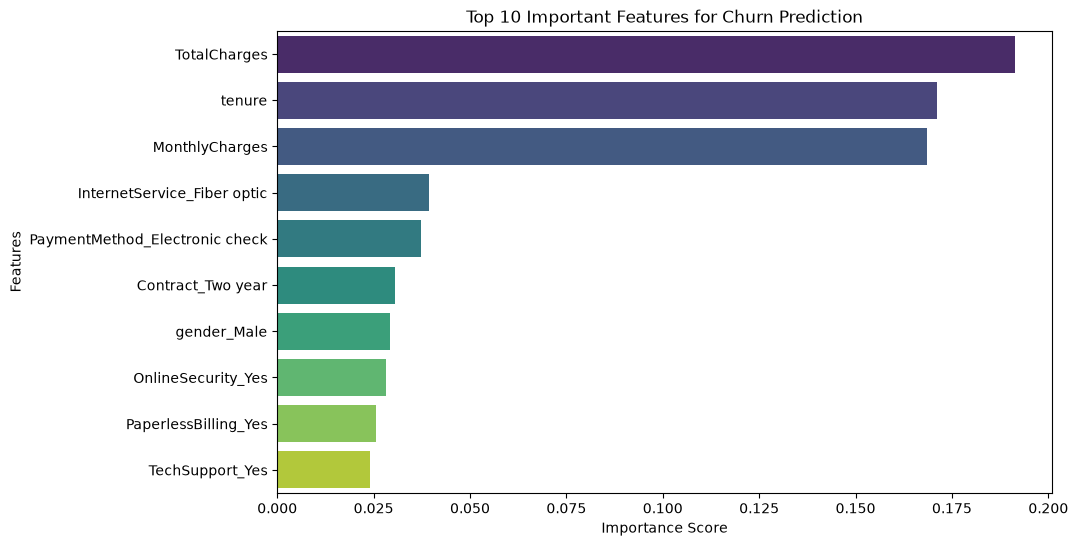

In [7]:
# استخراج اهمیت ویژگی‌ها از مدل Random Forest
feature_importances = pd.Series(model_rf.feature_importances_, index=X_train.columns)

# مرتب‌سازی و انتخاب ۱۰ ویژگی برتر
top_10_features = feature_importances.nlargest(10)

# رسم نمودار
plt.figure(figsize=(10, 6))
sns.barplot(x=top_10_features.values, y=top_10_features.index, palette='viridis')
plt.title('Top 10 Important Features for Churn Prediction')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

In [8]:
import joblib

# ذخیره مدل آموزش‌دیده در پوشه models
# (چون توی پوشه notebooks هستیم، باید یک پوشه عقب بریم)
joblib.dump(model_rf_balanced, '../models/churn_model.pkl')

print("مدل با موفقیت در پوشه models ذخیره شد! ✅")

مدل با موفقیت در پوشه models ذخیره شد! ✅


In [9]:
import joblib

# ذخیره مدل آموزش‌دیده در پوشه models
# (چون توی پوشه notebooks هستیم، باید یک پوشه عقب بریم)
joblib.dump(model_rf_balanced, '../models/churn_model.pkl')

print("مدل با موفقیت در پوشه models ذخیره شد! ✅")

مدل با موفقیت در پوشه models ذخیره شد! ✅
